In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

pd.set_option("display.max_columns", None)

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [2]:
df = pd.read_csv(
    "dataset/Sample - Superstore.csv",
    encoding="latin1"
)

print("Dataset Loaded Successfully!")
print("Shape:", df.shape)

Dataset Loaded Successfully!
Shape: (9994, 21)


In [3]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [4]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Number of Rows: 9994
Number of Columns: 21

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 

In [5]:
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values[missing_values > 0])

Missing Values:
Series([], dtype: int64)


In [6]:
# Convert date columns
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], errors="coerce")

# Remove duplicate records
df = df.drop_duplicates()

# Handle missing Postal Code values
if "Postal Code" in df.columns:
    df["Postal Code"] = df["Postal Code"].fillna(0)

print("Data Cleaning Completed!")
print("Updated Shape:", df.shape)

Data Cleaning Completed!
Updated Shape: (9994, 21)


In [7]:
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.month_name()

df["Profit Margin"] = (df["Profit"] / df["Sales"]) * 100

df["Shipping Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

print("Feature Engineering Completed!")

Feature Engineering Completed!


In [8]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()

print("========== SALES KPI ==========")
print(f"Total Sales      : ${total_sales:,.2f}")
print(f"Total Profit     : ${total_profit:,.2f}")
print(f"Total Quantity   : {total_quantity:,}")
print(f"Total Orders     : {total_orders:,}")
print(f"Total Customers  : {total_customers:,}")
print(f"Profit Margin    : {(total_profit / total_sales) * 100:.2f}%")

========== SALES KPI ==========
Total Sales      : $2,297,200.86
Total Profit     : $286,397.02
Total Quantity   : 37,873
Total Orders     : 5,009
Total Customers  : 793
Profit Margin    : 12.47%


In [9]:
category_sales = (
    df.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print("Sales by Category:")
print(category_sales)

Sales by Category:
Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64


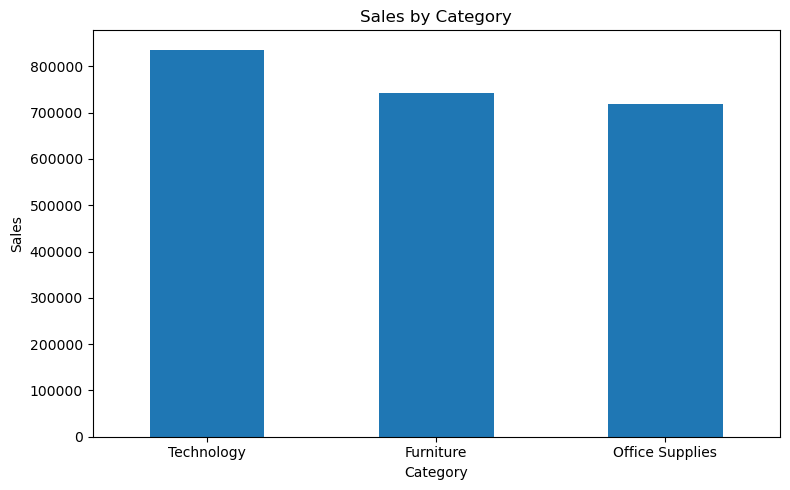

In [10]:
plt.figure(figsize=(8, 5))

category_sales.plot(
    kind="bar",
    title="Sales by Category"
)

plt.xlabel("Category")
plt.ylabel("Sales")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig("charts/sales_by_category.png", dpi=300)

plt.show()

In [11]:
category_profit = (
    df.groupby("Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

print("Profit by Category:")
print(category_profit)

Profit by Category:
Category
Technology         145454.9481
Office Supplies    122490.8008
Furniture           18451.2728
Name: Profit, dtype: float64


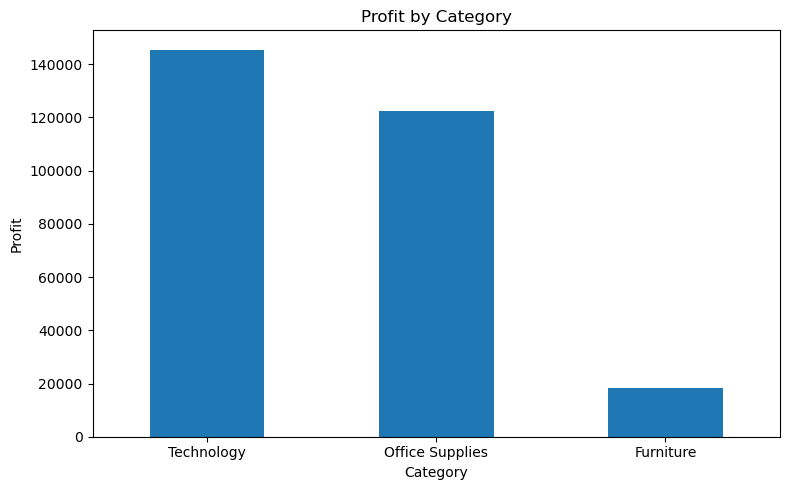

In [12]:
plt.figure(figsize=(8, 5))

category_profit.plot(
    kind="bar",
    title="Profit by Category"
)

plt.xlabel("Category")
plt.ylabel("Profit")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig("charts/profit_by_category.png", dpi=300)

plt.show()

In [13]:
region_sales = (
    df.groupby("Region")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print("Sales by Region:")
print(region_sales)

Sales by Region:
Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64


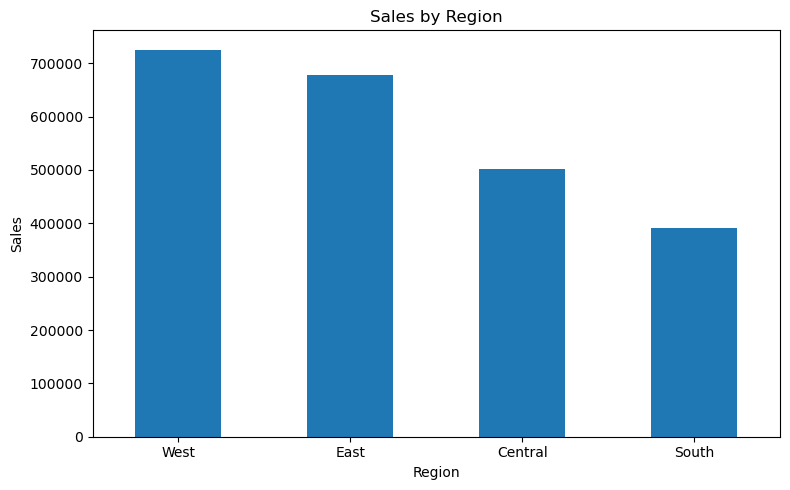

In [14]:
plt.figure(figsize=(8, 5))

region_sales.plot(
    kind="bar",
    title="Sales by Region"
)

plt.xlabel("Region")
plt.ylabel("Sales")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig("charts/sales_by_region.png", dpi=300)

plt.show()

In [15]:
monthly_sales = (
    df.groupby("Order Date")["Sales"]
    .sum()
    .sort_index()
)

print("Monthly Sales Data:")
print(monthly_sales.head(10))

Monthly Sales Data:
Order Date
2014-01-03      16.448
2014-01-04     288.060
2014-01-05      19.536
2014-01-06    4407.100
2014-01-07      87.158
2014-01-09      40.544
2014-01-10      54.830
2014-01-11       9.940
2014-01-13    3553.795
2014-01-14      61.960
Name: Sales, dtype: float64


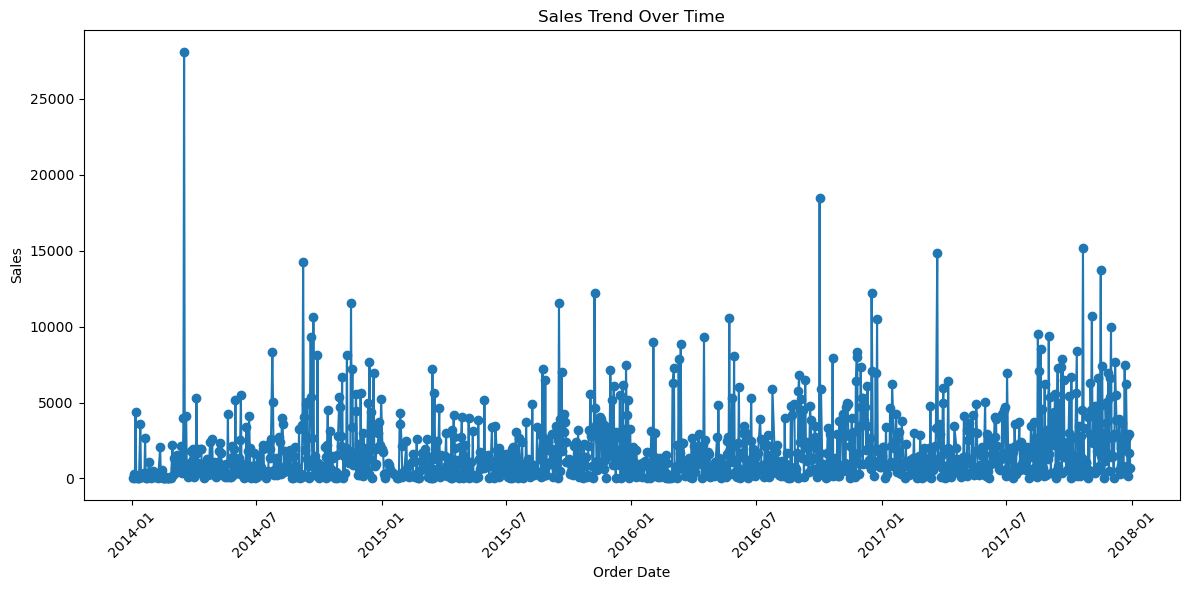

In [16]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)

plt.title("Sales Trend Over Time")
plt.xlabel("Order Date")
plt.ylabel("Sales")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig("charts/monthly_sales_trend.png", dpi=300)

plt.show()

In [17]:
top_products = (
    df.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Products by Sales:")
print(top_products)

Top 10 Products by Sales:
Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64


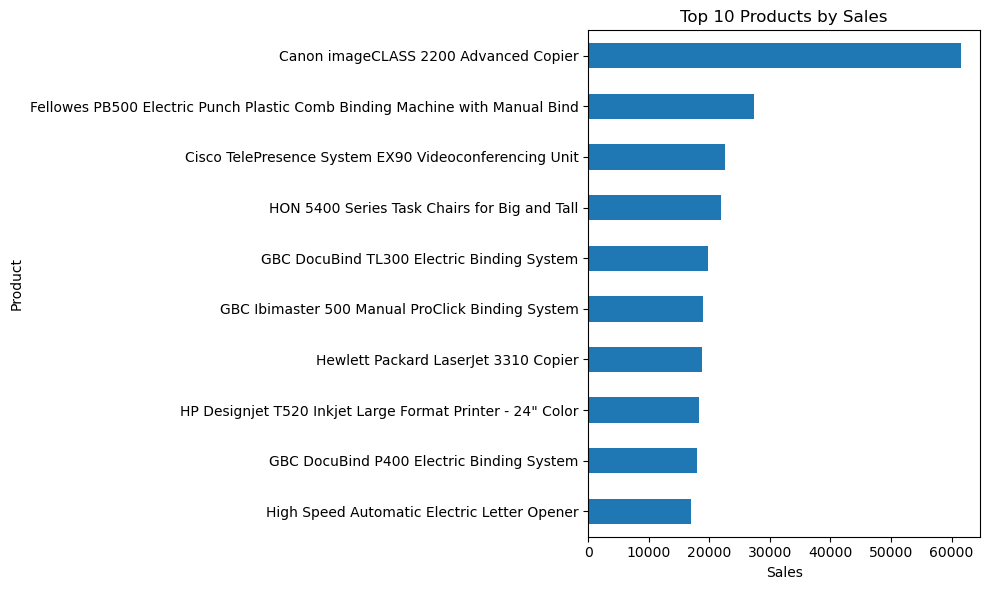

In [18]:
plt.figure(figsize=(10, 6))

top_products.sort_values().plot(
    kind="barh",
    title="Top 10 Products by Sales"
)

plt.xlabel("Sales")
plt.ylabel("Product")

plt.tight_layout()

plt.savefig("charts/top_10_products.png", dpi=300)

plt.show()

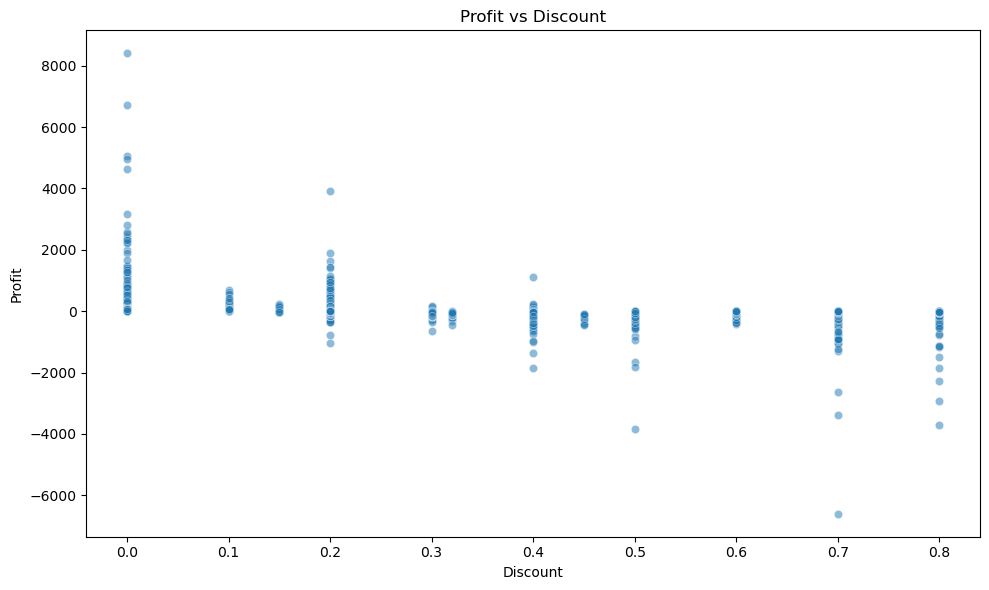

In [19]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Discount",
    y="Profit",
    alpha=0.5
)

plt.title("Profit vs Discount")
plt.xlabel("Discount")
plt.ylabel("Profit")

plt.tight_layout()

plt.savefig("charts/profit_vs_discount.png", dpi=300)

plt.show()

In [20]:
segment_sales = (
    df.groupby("Segment")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print("Sales by Customer Segment:")
print(segment_sales)

Sales by Customer Segment:
Segment
Consumer       1.161401e+06
Corporate      7.061464e+05
Home Office    4.296531e+05
Name: Sales, dtype: float64


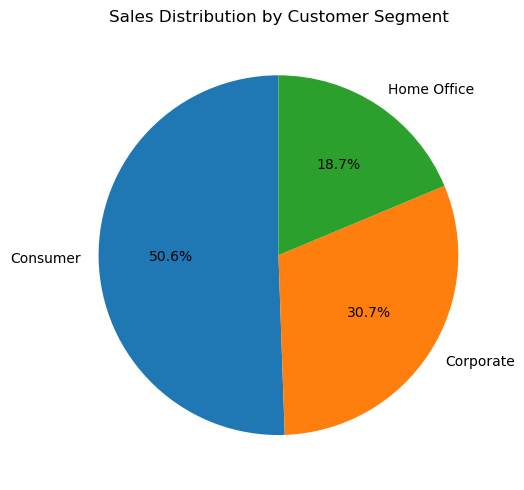

In [21]:
plt.figure(figsize=(8, 5))

segment_sales.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90,
    title="Sales Distribution by Customer Segment"
)

plt.ylabel("")

plt.tight_layout()

plt.savefig("charts/sales_by_segment.png", dpi=300)

plt.show()

In [22]:
product_profit = (
    df.groupby("Product Name")["Profit"]
    .sum()
    .sort_values()
)

print("========== TOP 5 PROFITABLE PRODUCTS ==========")
print(product_profit.tail(5))

print("\n========== TOP 5 LOSS-MAKING PRODUCTS ==========")
print(product_profit.head(5))

========== TOP 5 PROFITABLE PRODUCTS ==========
Product Name
HP Designjet T520 Inkjet Large Format Printer - 24" Color                       4094.9766
Canon PC1060 Personal Laser Copier                                              4570.9347
Hewlett Packard LaserJet 3310 Copier                                            6983.8836
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind     7753.0390
Canon imageCLASS 2200 Advanced Copier                                          25199.9280
Name: Profit, dtype: float64

========== TOP 5 LOSS-MAKING PRODUCTS ==========
Product Name
Cubify CubeX 3D Printer Double Head Print                  -8879.9704
Lexmark MX611dhe Monochrome Laser Printer                  -4589.9730
Cubify CubeX 3D Printer Triple Head Print                  -3839.9904
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases   -2876.1156
Bush Advantage Collection Racetrack Conference Table       -1934.3976
Name: Profit, dtype: float64


In [27]:
best_category = category_sales.idxmax()
best_region = region_sales.idxmax()
best_segment = segment_sales.idxmax()
most_profitable_category = category_profit.idxmax()

profit_margin = (total_profit / total_sales) * 100

print("========== BUSINESS INSIGHTS ==========")

print(f"1. Highest sales category     : {best_category}")
print(f"2. Highest sales region       : {best_region}")
print(f"3. Highest sales segment      : {best_segment}")
print(f"4. Most profitable category   : {most_profitable_category}")
print(f"5. Overall profit margin      : {profit_margin:.2f}%")

========== BUSINESS INSIGHTS ==========
1. Highest sales category     : Technology
2. Highest sales region       : West
3. Highest sales segment      : Consumer
4. Most profitable category   : Technology
5. Overall profit margin      : 12.47%


In [29]:
# Interactive Category Analysis

print("Available Categories:")
print("1. Furniture")
print("2. Office Supplies")
print("3. Technology")

category_input = "Technology"

selected_data = df[df["Category"] == category_input]

sales = selected_data["Sales"].sum()
profit = selected_data["Profit"].sum()
quantity = selected_data["Quantity"].sum()

print("\n========== CATEGORY ANALYSIS ==========")
print("Category :", category_input)
print(f"Sales    : ${sales:,.2f}")
print(f"Profit   : ${profit:,.2f}")
print(f"Quantity : {quantity:,}")

Available Categories:
1. Furniture
2. Office Supplies
3. Technology

========== CATEGORY ANALYSIS ==========
Category : Technology
Sales    : $836,154.03
Profit   : $145,454.95
Quantity : 6,939


In [30]:
df.to_csv("sales_cleaned.csv", index=False)

print("Clean Dataset Saved Successfully!")
print("File: sales_cleaned.csv")

Clean Dataset Saved Successfully!
File: sales_cleaned.csv


In [31]:
print("=" * 60)
print("       SALES DATA ANALYTICS PROJECT COMPLETED")
print("=" * 60)

print(f"Total Sales       : ${total_sales:,.2f}")
print(f"Total Profit      : ${total_profit:,.2f}")
print(f"Total Orders      : {total_orders:,}")
print(f"Total Customers   : {total_customers:,}")
print(f"Profit Margin     : {profit_margin:.2f}%")
print(f"Best Category     : {best_category}")
print(f"Best Region       : {best_region}")
print(f"Best Segment      : {best_segment}")

print("=" * 60)
print("Analysis and visualizations completed successfully!")

       SALES DATA ANALYTICS PROJECT COMPLETED
Total Sales       : $2,297,200.86
Total Profit      : $286,397.02
Total Orders      : 5,009
Total Customers   : 793
Profit Margin     : 12.47%
Best Category     : Technology
Best Region       : West
Best Segment      : Consumer
Analysis and visualizations completed successfully!
